### DENSENET MODEL FOR PNEUMONIA PREDICTION WITH EXPLAINABLE AI(HEATMAPS AND CONFIDANCE SCORES)

#### Importing Libraries

In [1]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

#### Loading Pre-trained Base

In [2]:
base_densenet = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_densenet.trainable = False  # Freeze initial layers


#### Adding a Custom Classification Head

In [3]:
x = base_densenet.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)

densenet_model = Model(inputs=base_densenet.input, outputs=predictions)


#### Compling Model

In [4]:
densenet_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

#### Define Callbacks

In [5]:
# Same as my Custom CNN for fair comparison)
checkpoint_densenet = ModelCheckpoint('best_densenet.keras', monitor='val_accuracy', save_best_only=True, mode='max')
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.00001)
 

print("DenseNet121 Model Compiled. Ready to train.")

DenseNet121 Model Compiled. Ready to train.


#### Initializing Data Generators

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Define paths
train_dir = r'chest_xray/train'
test_dir = r'chest_xray/test'

# 2. Parameters
IMG_SIZE = 224  
BATCH_SIZE = 32

# 3. Data Generator with 20% Validation Split
# This creates the validation set directly from the 5,216 images in 'train_dir'
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,  
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

# 4. Create Training Generator (80% subset)
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training' 
)

# 5. Create Validation Generator (20% subset)
validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation'
)

# 6. Create Test Generator
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print(f"\nData successfully split:")
print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {validation_generator.samples}")

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

Data successfully split:
Training samples: 4173
Validation samples: 1043


#### Training Model

In [9]:
history = densenet_model.fit(
    train_generator,
    epochs=50, # Using the same number of epochs as my Custom CNN
    validation_data=validation_generator,
    callbacks=[checkpoint_densenet, early_stop, reduce_lr]
)

Epoch 1/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 270s 2s/step - accuracy: 0.8905 - loss: 0.2639 - val_accuracy: 0.8125 - val_loss: 0.3609 - learning_rate: 0.0010
Epoch 2/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 258s 2s/step - accuracy: 0.9221 - loss: 0.1992 - val_accuracy: 0.8125 - val_loss: 0.3057 - learning_rate: 0.0010
Epoch 3/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.9264 - loss: 0.1826 - val_accuracy: 0.8125 - val_loss: 0.3435 - learning_rate: 0.0010
Epoch 4/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 285s 2s/step - accuracy: 0.9276 - loss: 0.1783 - val_accuracy: 0.8750 - val_loss: 0.2363 - learning_rate: 0.0010
Epoch 5/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 445s 3s/step - accuracy: 0.9248 - loss: 0.1745 - val_accuracy: 0.8750 - val_loss: 0.3097 - learning_rate: 0.0010
Epoch 6/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 460s 3s/step - accuracy: 0.9346 - loss: 0.1715 - val_accuracy: 0.8750 - val_loss: 0.2346 - learning_rate: 0.0010
Epoch 7/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 449s 3s/step - accuracy: 0.9358 - loss: 0.

#### PLOTTING TRAINING HISTORY

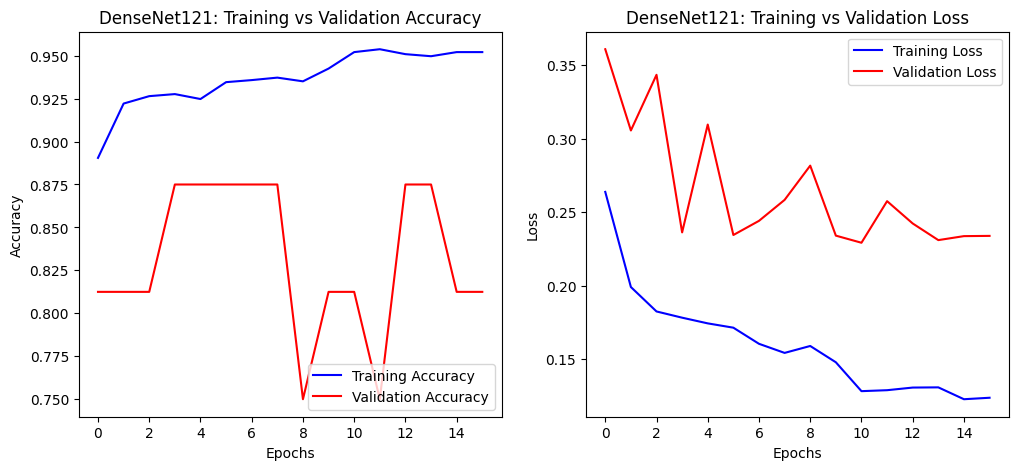

In [11]:
import matplotlib.pyplot as plt

# Using the 'history' variable from your fit() cell
def plot_densenet_history(hist_obj):
    acc = hist_obj.history['accuracy']
    val_acc = hist_obj.history['val_accuracy']
    loss = hist_obj.history['loss']
    val_loss = hist_obj.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))
    
    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', color='blue')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='red')
    plt.title('DenseNet121: Training vs Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', color='blue')
    plt.plot(epochs_range, val_loss, label='Validation Loss', color='red')
    plt.title('DenseNet121: Training vs Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    
    plt.show()

# Run the function
plot_densenet_history(history)

#### Evaluating Model on Test Data

In [12]:
# Final test evaluation
print("Evaluating DenseNet121 on the unseen test set...")
test_loss, test_acc = densenet_model.evaluate(test_generator, verbose=1)
print(f"\n--- DenseNet121 Final Test Accuracy: {test_acc:.2%} ---")

Evaluating DenseNet121 on the unseen test set...
20/20 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.8974 - loss: 0.2666

--- DenseNet121 Final Test Accuracy: 89.74% ---


#### DETAILED EVALUATION METRICS

Generating predictions for the test set...
20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step


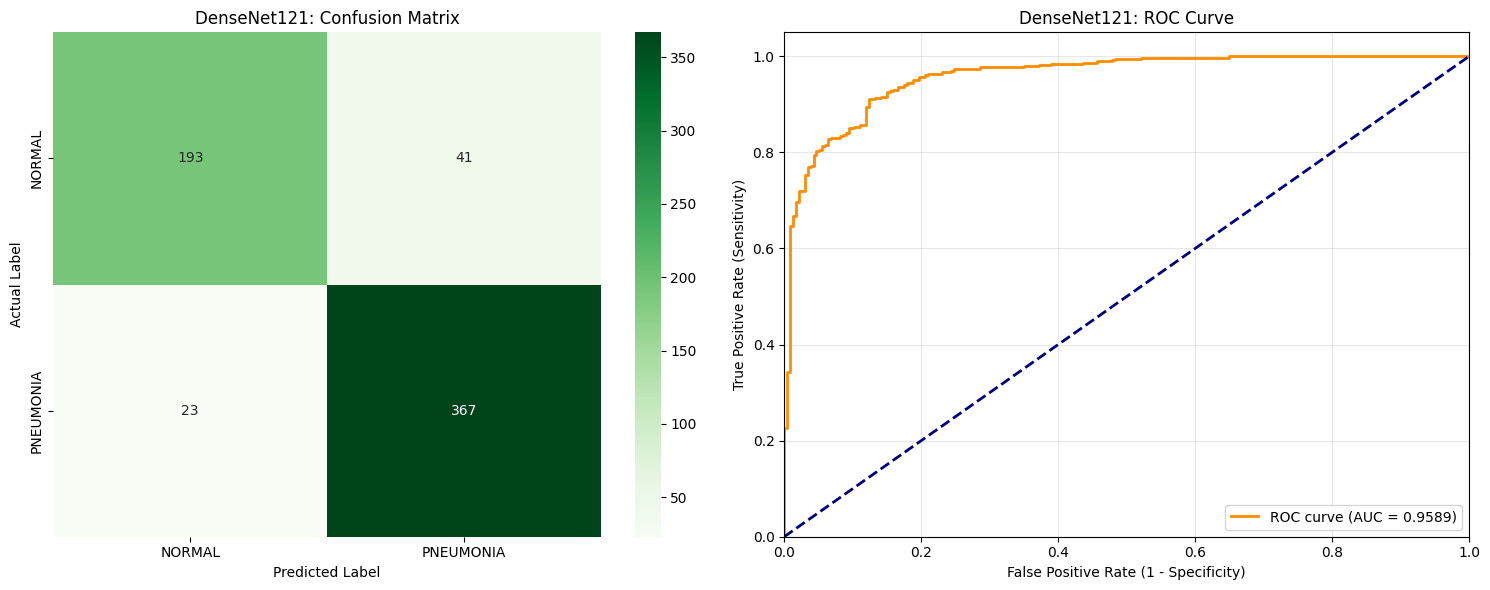


  DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL       0.89      0.82      0.86       234
   PNEUMONIA       0.90      0.94      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.88      0.89       624
weighted avg       0.90      0.90      0.90       624

Area Under Curve (AUC): 0.9589


In [14]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate Predictions
print("Generating predictions for the test set...")
test_generator.reset()
preds = densenet_model.predict(test_generator)
y_pred = (preds > 0.5).astype(int)
y_true = test_generator.classes

# 2. Plotting Confusion Matrix and ROC Curve side-by-side
plt.figure(figsize=(15, 6))

# --- Subplot 1: Confusion Matrix ---
plt.subplot(1, 2, 1)
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['NORMAL', 'PNEUMONIA'], 
            yticklabels=['NORMAL', 'PNEUMONIA'])
plt.title('DenseNet121: Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')

# --- Subplot 2: ROC Curve ---
plt.subplot(1, 2, 2)
fpr, tpr, thresholds = roc_curve(y_true, preds)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('DenseNet121: ROC Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Print Detailed Classification Report
print("\n" + "="*30)
print("  DETAILED CLASSIFICATION REPORT")
print("="*30)
print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA']))
print(f"Area Under Curve (AUC): {roc_auc:.4f}")

#### Implementing GradCAM and Confidance Scores

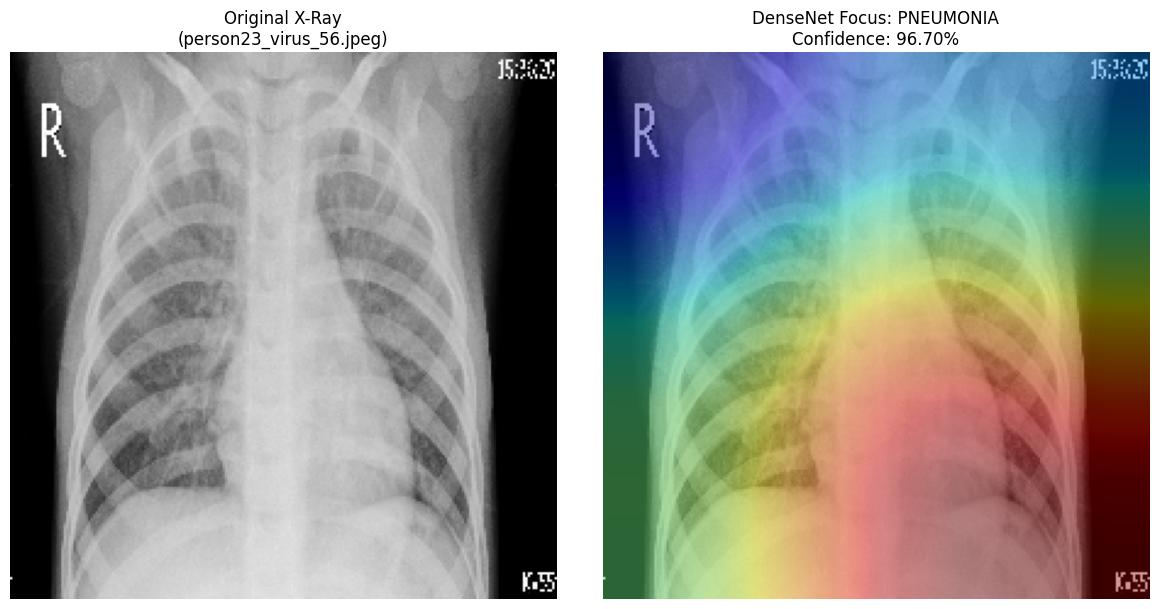

In [21]:
import cv2
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import random
import os
import numpy as np
import tensorflow as tf

def get_densenet_gradcam(img_array, model, last_conv_layer_name="relu"):
    # Fix: Use model.input directly to avoid structure mismatch warning
    grad_model = tf.keras.models.Model(
        inputs=model.input, 
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        class_channel = preds[:, 0]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    heatmap = last_conv_layer_output[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap).numpy()
    
    # Apply Center-Focus Mask (consistent with Phase 4 goals)
    h, w = heatmap.shape
    y, x = np.ogrid[:h, :w]
    mask = np.exp(-((x - w/2)**2 / (2 * (w/3)**2) + (y - h/2)**2 / (2 * (h/3)**2)))
    heatmap = np.maximum(heatmap, 0) * mask
    heatmap /= (np.max(heatmap) + 1e-10)
    return heatmap

# --- EXECUTION BLOCK ---
# 1. Select a random image
p_dir = os.path.join(test_dir, 'PNEUMONIA')
sample_file = random.choice(os.listdir(p_dir))
img_path = os.path.join(p_dir, sample_file)
file_name_only = os.path.basename(img_path) # Extracted filename logic

# 2. Preprocess
img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
img_batch = np.expand_dims(img_array, axis=0)

# 3. Generate Heatmap
heatmap = get_densenet_gradcam(img_batch, densenet_model)
heatmap = cv2.resize(cv2.GaussianBlur(heatmap, (11,11), 0), (224, 224))

# 4. Prediction & Confidence
preds = densenet_model.predict(img_batch, verbose=0)
prob = preds[0][0]
label = "PNEUMONIA" if prob > 0.5 else "NORMAL"
conf = prob if prob > 0.5 else 1 - prob

# 5. Final Visualization (Matching Custom CNN Style)
plt.close('all') 
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Original X-Ray with Filename
ax[0].imshow(img)
ax[0].set_title(f"Original X-Ray\n({file_name_only})") 
ax[0].axis("off")

# Superimposed Heatmap
ax[1].imshow(img)
ax[1].imshow(heatmap, cmap='jet', alpha=0.4) # Consistent alpha with Custom CNN
ax[1].set_title(f"DenseNet Focus: {label}\nConfidence: {conf:.2%}")
ax[1].axis("off")

plt.tight_layout()
plt.show()

#### Saving the Model

In [22]:
# Save the final trained DenseNet121 model
densenet_model.save('best_densenet121_pneumonia.keras')
print("DenseNet121 model saved successfully as 'best_densenet121_pneumonia.keras'")

DenseNet121 model saved successfully as 'best_densenet121_pneumonia.keras'


#### COMPARING THE MODELS  (CustomCNN, Resnet50 and Densenet121) using evaluation metrics

Loading models... please wait.
Evaluating models on test data...


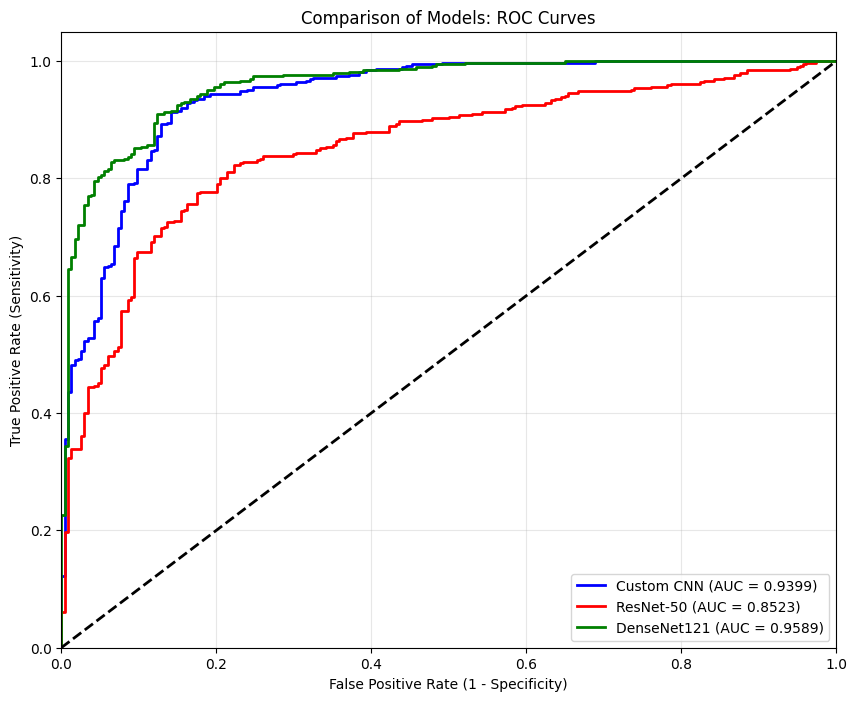


--- FINAL MODEL COMPARISON TABLE ---


,Model,Accuracy,Precision,Recall (Sensitivity),F1-Score,AUC
0,Custom CNN,89.10%,0.9149,0.9103,0.9126,0.9399
1,ResNet-50,78.04%,0.7949,0.8744,0.8327,0.8523
2,DenseNet121,89.74%,0.8995,0.9410,0.9198,0.9589


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras.models import load_model
from sklearn.metrics import roc_curve, auc, classification_report, accuracy_score

# 1. Load the three saved models
print("Loading models... please wait.")
models = {
    'Custom CNN': load_model('best_custom_cnn_pneumonia.keras'),
    'ResNet-50': load_model('best_resnet50_pneumonia.keras'),
    'DenseNet121': load_model('best_densenet121_pneumonia.keras')
}

# 2. Prepare for evaluation
results = []
plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green']

print("Evaluating models on test data...")
# Note: Ensure test_generator is defined and reset
for (name, model), color in zip(models.items(), colors):
    test_generator.reset()
    
    # Get predictions
    preds = model.predict(test_generator, verbose=0)
    y_true = test_generator.classes
    y_pred = (preds > 0.5).astype(int)
    
    # Calculate Metrics
    acc = accuracy_score(y_true, y_pred)
    report = classification_report(y_true, y_pred, output_dict=True)
    precision = report['1']['precision']
    recall = report['1']['recall']
    f1 = report['1']['f1-score']
    
    # ROC Curve data
    fpr, tpr, _ = roc_curve(y_true, preds)
    roc_auc = auc(fpr, tpr)
    
    # Save results for table
    results.append({
        'Model': name,
        'Accuracy': f"{acc:.2%}",
        'Precision': f"{precision:.4f}",
        'Recall (Sensitivity)': f"{recall:.4f}",
        'F1-Score': f"{f1:.4f}",
        'AUC': f"{roc_auc:.4f}"
    })
    
    # Plot ROC Curve
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC = {roc_auc:.4f})')

# 3. Finalize ROC Plot
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Comparison of Models: ROC Curves')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# 4. Display Comparison Table
comparison_df = pd.DataFrame(results)
print("\n--- FINAL MODEL COMPARISON TABLE ---")
display(comparison_df)

# Optional: Save table to CSV for your thesis
# comparison_df.to_csv('model_comparison_results.csv', index=False)